# Microlensing Part B — Grid search
This notebook starts with OGLE-2024-BLG-0010. Open it in Colab and choose **Runtime → Run all**. The input cell fixes the peak time and blending fraction and scans 1,002,001 combinations of impact parameter and Einstein time.

Use **Grid best** and **Grid minimum chi-square** for the grid-search result. The notebook also prints the continuous refinement and uses it for the light-curve plots and profile uncertainty estimates. Corner plots use the grid.

For a different OGLE event, edit the data URL, reference parameters, fixed values, and grid in the input cell. To fit four parameters, use an empty `FIXED` dictionary and set suitable bounds for that event. The 0010 grid is evaluated in batches to limit temporary memory use.

In [13]:
# %pip install numpy scipy matplotlib

from itertools import combinations
from math import prod
from pathlib import Path
import re
from urllib.parse import urlsplit
from urllib.request import urlopen
from urllib.error import URLError
from time import perf_counter

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy.optimize import brentq, least_squares
from scipy.stats import chi2, norm
from IPython.display import Image, display

## Event inputs

In [14]:
OGLE_URL = "https://www.astrouw.edu.pl/ogle/ogle4/ews/2024/blg-0010/phot.dat"

# Reference values and their uncertainties. Peak time is in full HJD.
GUESSES = {
    "t0": (2460383.536,  0.121),
    "u0": (0.500, 0.002),
    "tE": (11.795,  0.495),
    "b": (1.0, None),
}

FIXED = {"t0": GUESSES["t0"][0], "b": 1.0}

# Each tuple is (minimum, maximum, step).
GRID = {
    "u0": (0.40, 0.60, 0.0002),
    "tE": (7.0, 15.0, 0.008),
}

ZOOM_HALF_WIDTH = None
OUTPUT_DIR = Path("part_b_results")

## Photometry and chi-square grid

In [15]:
PARAMETERS = ("t0", "u0", "tE", "b")
HJD_OFFSET = 2450000
LABELS = {
    "t0": r"$t_0-2450000$ [HJD days]",
    "u0": r"$u_0$ (dimensionless)",
    "tE": r"$t_E$ [days]",
    "b": r"$f_{\rm bl}$",
}
SIGMAS = np.arange(1, 4)
LEVELS = chi2.ppf(2 * norm.cdf(SIGMAS) - 1, df=2)
COLORS = ("#1565a1", "#ad4b0a", "#734895")


def load_photometry(url):
    match = re.search(r"/ews/(\d{4})/(blg-\d+)/phot\.dat$", urlsplit(url).path, re.I)
    event = f"OGLE-{match[1]}-{match[2].upper()}" if match else "OGLE-event"
    try:
        with urlopen(url, timeout=45) as response:
            data = np.loadtxt(response, usecols=(0, 1, 2), ndmin=2)
    except URLError as exc:
        raise RuntimeError(f"Could not download photometry from {url}: {exc.reason}") from exc
    except ValueError as exc:
        raise ValueError("Use the direct URL of an OGLE phot.dat data file.") from exc
    valid = np.isfinite(data).all(axis=1) & (data[:, 2] > 0)
    return event, data[valid].T, int((~valid).sum())


def validate_parameter(name, value):
    if not np.isfinite(value):
        raise ValueError(f"{name} must be finite")
    if name in ("tE", "u0") and value <= 0:
        raise ValueError(f"{name} must be positive")
    if name == "b" and not 0 < value <= 1:
        raise ValueError("b must satisfy 0 < b <= 1")


def make_axes(config):
    axes = []
    for name in PARAMETERS:
        validate_parameter(name, config["guess"][name])
        if name in config["fixed"]:
            value = config["fixed"][name]
            validate_parameter(name, value)
            axes.append(np.array([value]))
            continue
        low, high, step = config["grid"][name]
        validate_parameter(name, low)
        validate_parameter(name, high)
        if not np.isfinite(step) or step <= 0 or high <= low:
            raise ValueError(f"{name}: need min < max and a positive step")
        ratio = (high - low) / step
        count = round(ratio)
        if count < 1 or not np.isclose(ratio, count, atol=1e-6, rtol=0):
            raise ValueError(f"{name}: (max - min) must be a multiple of step")
        axis = low + step * np.arange(count + 1)
        axis[-1] = high  # Remove floating-point rounding at the endpoint.
        axes.append(axis)
    return axes


def amplification_excess(t, t0, u0, tE):
    """A(u) - 1, rationalized to retain precision far from the event."""
    u_squared = u0**2 + ((t - t0) / tE)**2
    denominator = np.sqrt(u_squared * (u_squared + 4))
    return 4 / (denominator * (u_squared + 2 + denominator))


def scan_grid_batch(axes, t, flux, error):
    """Evaluate every grid point, profiling the linear baseline flux.

    For g = 1 + b*(A-1), F_model = F_base*g.
    F_base = sum(w*g*F) / sum(w*g*g).
    chi2_min(F_base) = sum(w*F*F) - sum(w*g*F)**2 / sum(w*g*g).
    The required weighted sums are quadratic or linear in b. Compute the
    time-dependent terms once per (t0, u0, tE), then scan all b values.
    """
    time_axis, impact_axis, einstein_axis, blend_axis = axes
    shape = tuple(len(axis) for axis in axes)
    keys = [(i,) for i in range(4)] + list(combinations(range(4), 2))
    profiles = {key: np.full(tuple(shape[i] for i in key), np.inf) for key in keys}
    minimum = np.inf
    best_index = None
    weight = 1 / error**2
    weighted_flux = weight * flux
    sum_weight = weight.sum()
    sum_weighted_flux = weighted_flux.sum()
    flux_squared = np.dot(weighted_flux, flux)
    t = t - HJD_OFFSET
    blend = blend_axis[None, None, :]

    for index, t0 in enumerate(time_axis):
        excess = amplification_excess(
            t, t0 - HJD_OFFSET, impact_axis[:, None, None],
            einstein_axis[None, :, None],
        )
        weighted_excess = np.einsum("ijt,t->ij", excess, weight)
        weighted_excess_squared = np.einsum("ijt,ijt,t->ij", excess, excess, weight)
        weighted_excess_flux = np.einsum("ijt,t->ij", excess, weighted_flux)
        numerator = sum_weighted_flux + blend * weighted_excess_flux[..., None]
        denominator = (sum_weight + 2 * blend * weighted_excess[..., None]
                       + blend**2 * weighted_excess_squared[..., None])
        slab = np.maximum(flux_squared - numerator**2 / denominator, 0)
        local_index = np.unravel_index(np.argmin(slab), slab.shape)
        if slab[local_index] < minimum:
            minimum = slab[local_index]
            best_index = (index, *local_index)
        for key, values in profiles.items():
            reduce = tuple(i - 1 for i in range(1, 4) if i not in key)
            projected = slab.min(axis=reduce)
            if 0 in key:
                values[index] = projected
            else:
                np.minimum(values, projected, out=values)
    for values in profiles.values():
        values -= minimum
    return minimum, best_index, profiles



def scan_grid(axes, t, flux, error):
    """Batch the two-parameter scan along u0 and merge its profiles."""
    if len(axes[0]) > 1 or len(axes[3]) > 1:
        return scan_grid_batch(axes, t, flux, error)

    # Limit the number of elements in each temporary magnification array.
    elements_per_row = len(axes[2]) * len(t)
    rows_per_batch = max(1, min(16, 1_000_000 // elements_per_row))
    best_chi = np.inf
    best_index = None
    profiles = {}

    for start in range(0, len(axes[1]), rows_per_batch):
        stop = min(start + rows_per_batch, len(axes[1]))
        batch_axes = [axes[0], axes[1][start:stop], axes[2], axes[3]]
        batch_chi, index, batch_profiles = scan_grid_batch(
            batch_axes, t, flux, error
        )
        if batch_chi < best_chi:
            best_chi = batch_chi
            best_index = (index[0], start + index[1], index[2], index[3])

        for key, delta_chi in batch_profiles.items():
            if key not in profiles:
                shape = tuple(len(axes[i]) for i in key)
                profiles[key] = np.full(shape, np.inf)

            # Each batch reports chi-square relative to its own minimum.
            absolute_chi = delta_chi + batch_chi
            if 1 in key:
                target = [slice(None)] * len(key)
                target[key.index(1)] = slice(start, stop)
                profiles[key][tuple(target)] = absolute_chi
            else:
                np.minimum(profiles[key], absolute_chi, out=profiles[key])

    for profile in profiles.values():
        profile -= best_chi
    return best_chi, best_index, profiles


## Figures

In [16]:
def save_corner(output, title, config, axes, profiles, best):
    free = [i for i, axis in enumerate(axes) if len(axis) > 1]
    if not free:
        return
    n = len(free)
    fig, panels = plt.subplots(n, n, squeeze=False, figsize=(3.25*n, 2.85*n + 1.1))
    fig.suptitle(title + "  |  Profile " + r"$\Delta\chi^2$", y=0.98)
    shown_axes = [axis - HJD_OFFSET if i == 0 else axis for i, axis in enumerate(axes)]
    shown_best = best.copy()
    shown_best[0] -= HJD_OFFSET
    shown_guess = np.array([config["guess"][name] for name in PARAMETERS])
    shown_guess[0] -= HJD_OFFSET
    view = {}
    for i in free:
        axis = shown_axes[i]
        inside = np.flatnonzero(profiles[i,] <= LEVELS[-1])
        first = max(0, inside[0] - 1)
        last = min(len(axis) - 1, inside[-1] + 1)
        low, high = axis[first], axis[last]
        if axis[0] <= shown_guess[i] <= axis[-1]:
            low = min(low, shown_guess[i])
            high = max(high, shown_guess[i])
        pad = 0.10 * (high - low)
        view[i] = (max(axis[0], low - pad), min(axis[-1], high + pad))

    for row, i in enumerate(free):
        for col, j in enumerate(free):
            panel = panels[row, col]
            if row < col:
                panel.set_axis_off()
                continue
            x = shown_axes[j]
            if i == j:
                curve = profiles[i,]
                panel.plot(x, curve, color="#203a55", lw=1.4)
                panel.axhline(1, color=COLORS[0], ls=":", lw=1)
                panel.axvline(shown_best[i], color="#152432", lw=1)
                if x[0] <= shown_guess[i] <= x[-1]:
                    panel.axvline(shown_guess[i], color="#c74450", ls="--", lw=1)
                panel.set_ylim(0, 10)
                panel.set_ylabel(r"$\Delta\chi^2$")
            else:
                y = shown_axes[i]
                surface = profiles[j, i].T
                levels = [(value, color) for value, color in zip(LEVELS, COLORS)
                          if surface.min() < value < surface.max()]
                if levels:
                    panel.contour(x, y, surface, levels=[p[0] for p in levels],
                                  colors=[p[1] for p in levels], linewidths=1.4)
                panel.plot(shown_best[j], shown_best[i], "o", ms=4, color="#152432")
                if x[0] <= shown_guess[j] <= x[-1] and y[0] <= shown_guess[i] <= y[-1]:
                    panel.plot(shown_guess[j], shown_guess[i], "x", ms=6, color="#c74450")
                panel.set_ylim(*view[i])
                panel.set_ylabel(LABELS[PARAMETERS[i]])
            panel.set_xlim(*view[j])
            if row == n - 1:
                panel.set_xlabel(LABELS[PARAMETERS[j]])
            panel.xaxis.set_major_locator(MaxNLocator(4))
            panel.yaxis.set_major_locator(MaxNLocator(4))
            panel.ticklabel_format(useOffset=False, axis="both")
            panel.grid(alpha=0.14)
    handles = [Line2D([], [], color=color, label=fr"${sigma}\sigma$ joint")
               for sigma, color in zip(SIGMAS, COLORS)] if n >= 2 else []
    handles.extend([
        Line2D([], [], color="#152432", marker="o", label="Grid minimum"),
        Line2D([], [], color="#c74450", marker="x", ls="--", label="Initial guess"),
    ])
    fig.legend(handles=handles, loc="lower center", ncol=3 if n >= 2 else 2, frameon=False)
    fig.tight_layout(rect=(0.02, 0.10 if n <= 2 else 0.07, 1, 0.95))
    for extension in ("png", "pdf"):
        fig.savefig(output / f"corner.{extension}", dpi=200)
    plt.close(fig)


def save_light_curve(output, title, t, mag, error_mag, best, baseline_mag,
                     residual, zoom_half_width=None):
    t0, _, tE, _ = best
    time_model = np.unique(np.r_[np.linspace(t.min(), t.max(), 2500),
                                 np.linspace(t0 - 3*tE, t0 + 3*tE, 1500)])
    time_model = time_model[(time_model >= t.min()) & (time_model <= t.max())]
    model = baseline_mag - 2.5 * np.log10(
        1 + best[3] * amplification_excess(time_model, *best[:3])
    )
    fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(9, 5.4),
                                      gridspec_kw={"height_ratios": [3, 1]})
    top.errorbar(t-HJD_OFFSET, mag, yerr=error_mag, fmt=".", ms=3,
                 color="#687d8c", alpha=0.65, label="Photometry")
    top.plot(time_model-HJD_OFFSET, model, color="#1565a1", label="Best-fit blending model")
    top.invert_yaxis()
    top.set(ylabel="I magnitude", title=title)
    top.legend()
    bottom.scatter(t-HJD_OFFSET, residual, s=9, color="#687d8c")
    bottom.axhline(0, color="#152432", lw=1)
    bottom.set(xlabel="HJD − 2450000 [days]", ylabel=r"Residual / $\sigma_F$")
    if zoom_half_width is not None:
        window = np.abs(t - t0) <= zoom_half_width
        bottom.set_xlim(t0 - zoom_half_width - HJD_OFFSET, t0 + zoom_half_width - HJD_OFFSET)
        if window.any():
            bright = np.min(mag[window] - error_mag[window])
            faint = np.max(mag[window] + error_mag[window])
            model_window = np.abs(time_model - t0) <= zoom_half_width
            if model_window.any():
                bright = min(bright, model[model_window].min())
                faint = max(faint, model[model_window].max())
            padding = max(0.04, 0.08 * (faint - bright))
            top.set_ylim(faint + padding, bright - padding)
    fig.tight_layout()
    name = "light_curve_event" if zoom_half_width is not None else "light_curve_full"
    fig.savefig(output / f"{name}.png", dpi=180)
    plt.close(fig)




## Fit and comparison

In [17]:
def fitted_flux(t, flux, error, params):
    t0, u0, tE, b = params
    shape = 1 + b * amplification_excess(t, t0, u0, tE)
    weight = 1 / error**2
    baseline = np.dot(weight * shape, flux) / np.dot(weight, shape**2)
    return baseline, baseline * shape


def refine_fit(t, flux, error, axes, start, held=None):
    """Refit continuously within scan bounds, optionally holding a coordinate."""
    params = start.copy()
    if held is not None:
        params[held[0]] = held[1]
    free = [i for i, axis in enumerate(axes)
            if len(axis) > 1 and (held is None or i != held[0])]
    center = params[free]

    def residuals(offsets):
        trial = params.copy()
        trial[free] = center + offsets
        _, prediction = fitted_flux(t, flux, error, trial)
        return (flux - prediction) / error

    offsets = np.zeros(len(free))
    if free:
        low = np.array([axes[i][0] for i in free]) - center
        high = np.array([axes[i][-1] for i in free]) - center
        result = least_squares(residuals, offsets, bounds=(low, high),
                               x_scale=high - low, jac="3-point",
                               ftol=1e-12, xtol=1e-12, gtol=1e-10)
        if not result.success:
            raise RuntimeError(f"Continuous fit failed: {result.message}")
        offsets = result.x
    residual = residuals(offsets)
    params[free] = center + offsets
    return params, np.dot(residual, residual)


def build_config(guesses, fixed, grid):
    guess = {}
    errors = {}
    for name in PARAMETERS:
        value, error = guesses[name]
        validate_parameter(name, value)
        if error is not None and (not np.isfinite(error) or error <= 0):
            raise ValueError(f"{name}: use a positive guess uncertainty or None")
        guess[name], errors[name] = value, error

    # Automatic bounds are starting points. Widen them if the grid clips contours.
    fallback = (max(0.1, 0.05 * guess["tE"]), 0.6 * guess["u0"],
                0.6 * guess["tE"], 0.4)
    scan = dict(grid)
    for name, half_width in zip(PARAMETERS, fallback):
        if name in fixed or name in scan:
            continue
        center = guess[name]
        width = half_width if errors[name] is None else 5 * errors[name]
        low, high = center - width, center + width
        if name in ("u0", "tE", "b"):
            low = max(0.01 * center, low)
        if name == "b":
            high = min(1.0, high)
        scan[name] = (low, high, (high - low) / 100)
    return {"guess": guess, "guess_error": errors, "fixed": fixed, "grid": scan}


def run_event(url, config, output_root, zoom_half_width):
    event, (t, mag, mag_error), dropped = load_photometry(url)
    # OGLE releases can use either full HJD or HJD minus 2450000.
    if len(t) and 0 < np.median(t) < 100_000:
        t = t + HJD_OFFSET
    if not len(t) or not 2_000_000 < np.median(t) < 3_000_000:
        raise ValueError("Expected times in full HJD or HJD minus 2450000.")

    axes = make_axes(config)
    free = [i for i, axis in enumerate(axes) if len(axis) > 1]
    if not free:
        raise ValueError("Leave at least one parameter free.")
    dof = len(t) - len(free) - 1
    if dof <= 0:
        raise ValueError("Too few valid observations for this fit.")
    reference_mag = np.median(mag)
    flux = 10**(-0.4 * (mag - reference_mag))
    error = 0.4 * np.log(10) * flux * mag_error
    if not (np.isfinite(flux).all() and np.isfinite(error).all() and (error > 0).all()):
        raise ValueError("Invalid flux or uncertainty after conversion.")

    count = prod(map(len, axes))
    print(f"{event}: scanning {count:,} grid points", flush=True)
    start = perf_counter()
    grid_chi, index, profiles = scan_grid(axes, t, flux, error)
    grid_best = np.array([axis[i] for axis, i in zip(axes, index)])
    best, chi = refine_fit(t, flux, error, axes, grid_best)
    baseline, prediction = fitted_flux(t, flux, error, best)
    baseline_mag = reference_mag - 2.5 * np.log10(baseline)
    zoom = best[2] if zoom_half_width is None else zoom_half_width
    if not np.isfinite(zoom) or zoom <= 0:
        raise ValueError("ZOOM_HALF_WIDTH must be positive or None.")

    lines = [
        event, f"Data: {url}",
        f"Valid observations: {len(t)} | Discarded rows: {dropped}",
        f"Grid points: {count:,} | Fit time: {perf_counter() - start:.2f} s",
        f"Grid minimum chi-square: {grid_chi:.9f}",
        f"Refined minimum chi-square: {chi:.9f}",
        f"Degrees of freedom (includes fitted baseline): {dof}",
        f"Reduced chi-square: {chi / dof:.6f}",
        f"Fitted baseline magnitude: {baseline_mag:.6f}",
        "Combined N_sigma assumes independent uncertainties; with shared data it is descriptive.",
        "An unresolved interval indicates that Delta chi-square = 1 was not reached before the scan boundary.",
    ]
    for i, name in enumerate(PARAMETERS):
        guess = config["guess"][name]
        guess_error = config["guess_error"][name]
        lines.extend(["", f"{name}: fit={best[i]:.14g} | guess={guess:.14g} | guess uncertainty={guess_error}"])
        if i not in free:
            lines.append("  Fixed parameter; no fit uncertainty.")
            continue
        axis = axes[i]
        lines.append(f"  Grid best: {grid_best[i]:.14g} | bounds [{axis[0]:.14g}, {axis[-1]:.14g}] | step {axis[1]-axis[0]:.6g}")
        if index[i] in (0, len(axis) - 1) or min(profiles[i,][0], profiles[i,][-1]) <= LEVELS[-1]:
            lines.append("  A minimum or joint contour may reach a scan boundary.")
        def profile(value):
            return refine_fit(t, flux, error, axes, best, held=(i, value))[1] - chi

        intervals = []
        for boundary in (axis[0], axis[-1]):
            if profile(boundary) < 1:
                intervals.append(None)
                continue
            lo, hi = sorted((boundary, best[i]))
            crossing = brentq(lambda offset: profile(best[i] + offset) - 1,
                              lo - best[i], hi - best[i], xtol=1e-8)
            intervals.append(abs(crossing))
        lower, upper = intervals
        lower_text, upper_text = ("unresolved" if x is None else f"{x:.6g}" for x in intervals)
        difference = best[i] - guess
        lines.append(f"  Fit uncertainty (lower, upper): {lower_text}, {upper_text}")
        lines.append(f"  Fit minus guess: {difference:+.8g}")
        if axis[0] <= guess <= axis[-1]:
            lines.append(f"  Profile N_sigma at guess: {np.sqrt(max(0.0, profile(guess))):.8g}")
        else:
            lines.append("  Profile N_sigma unavailable: guess outside scan bounds.")
        toward_guess = lower if difference > 0 else upper
        if guess_error is not None and toward_guess is not None:
            combined = abs(difference) / np.hypot(toward_guess, guess_error)
            lines.append(f"  Combined N_sigma vs guess: {combined:.8g}")
        else:
            lines.append("  Combined N_sigma unavailable: missing guess uncertainty or unresolved fit interval.")

    output = output_root / event
    output.mkdir(parents=True, exist_ok=True)
    report = "\n".join(lines) + "\n"
    print(report)
    (output / "fit_summary.txt").write_text(report, encoding="utf-8")
    save_corner(output, event, config, axes, profiles, grid_best)
    residual = (flux - prediction) / error
    for half_width in (None, zoom):
        save_light_curve(output, event, t, mag, mag_error, best, baseline_mag, residual, half_width)
    return output


OGLE-2024-BLG-0010: scanning 1,002,001 grid points
OGLE-2024-BLG-0010
Data: https://www.astrouw.edu.pl/ogle/ogle4/ews/2024/blg-0010/phot.dat
Valid observations: 428 | Discarded rows: 0
Grid points: 1,002,001 | Fit time: 14.95 s
Grid minimum chi-square: 610.801243790
Refined minimum chi-square: 610.797230130
Degrees of freedom (includes fitted baseline): 425
Reduced chi-square: 1.437170
Fitted baseline magnitude: 16.372164
Combined N_sigma assumes independent uncertainties; with shared data it is descriptive.
An unresolved interval indicates that Delta chi-square = 1 was not reached before the scan boundary.

t0: fit=2460383.536 | guess=2460383.536 | guess uncertainty=0.121
  Fixed parameter; no fit uncertainty.

u0: fit=0.5056588272571 | guess=0.500351 | guess uncertainty=0.002
  Grid best: 0.5056 | bounds [0.4, 0.6] | step 0.0002
  Fit uncertainty (lower, upper): 0.0019568, 0.00196737
  Fit minus guess: +0.0053078273
  Profile N_sigma at guess: 2.7250504
  Combined N_sigma vs guess: 1

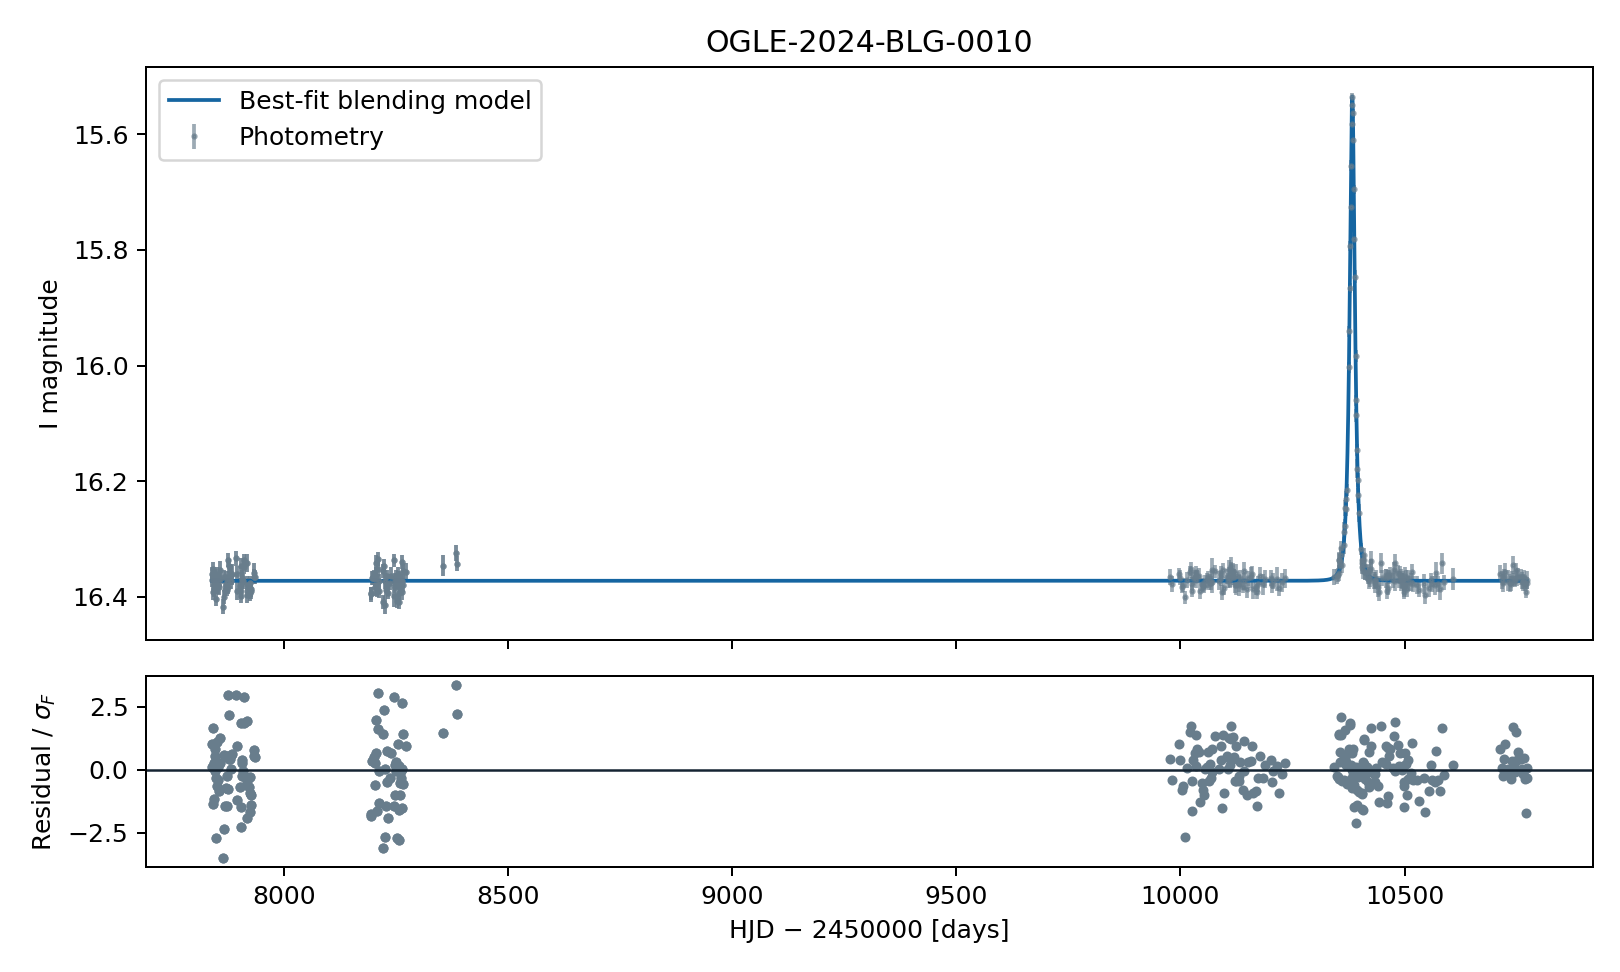

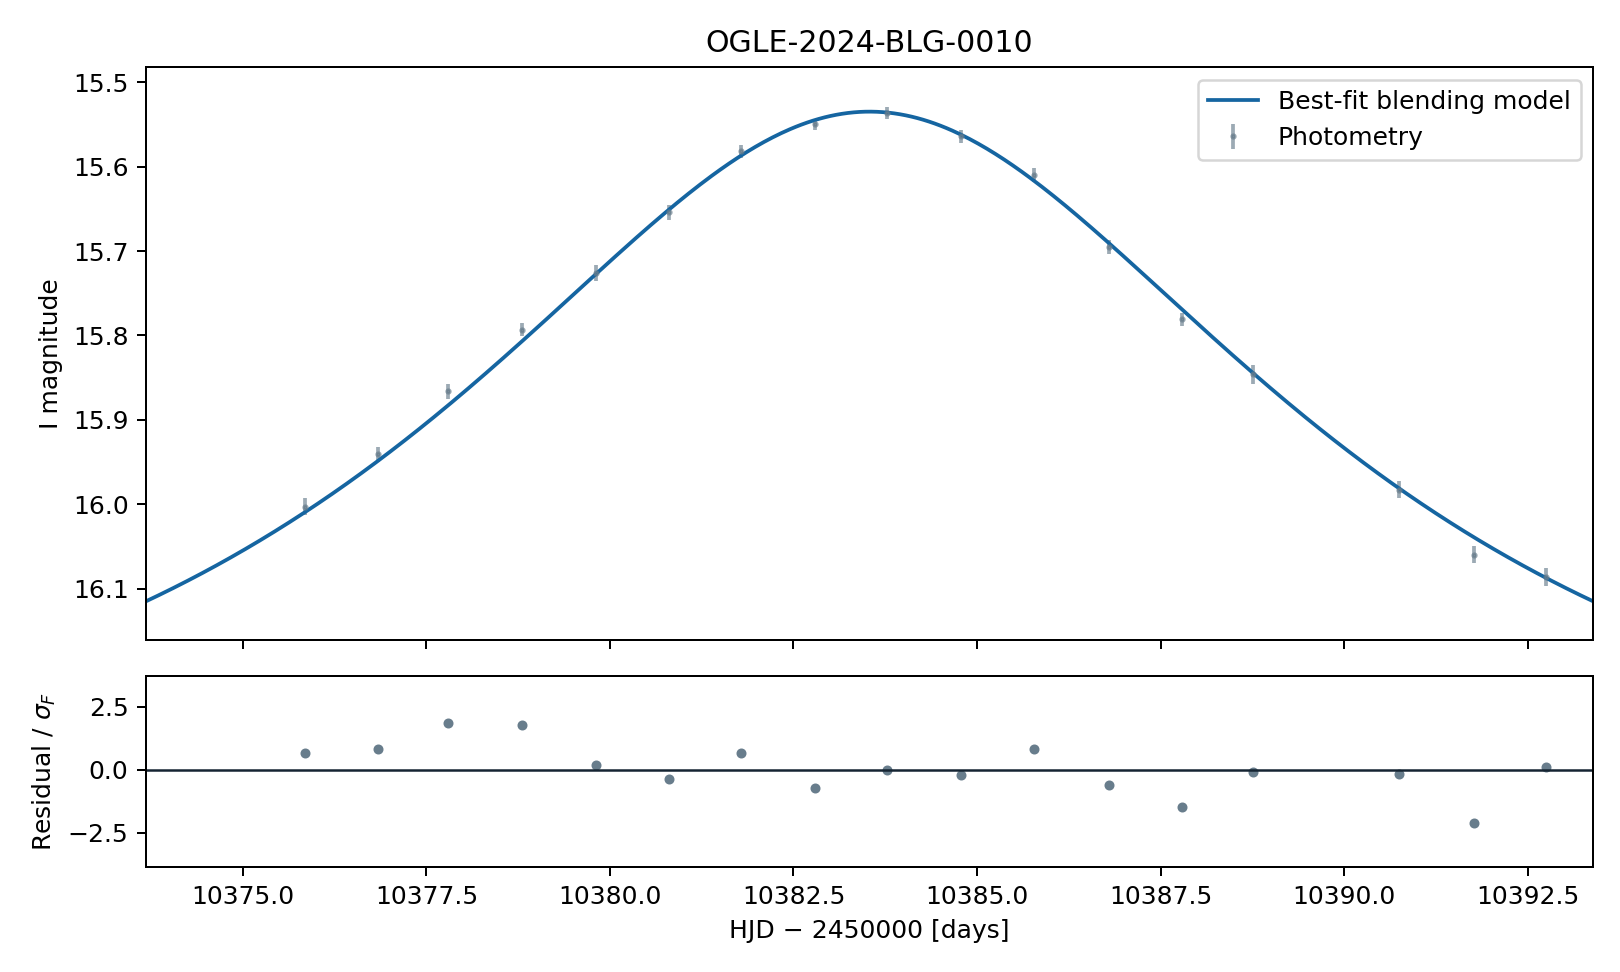

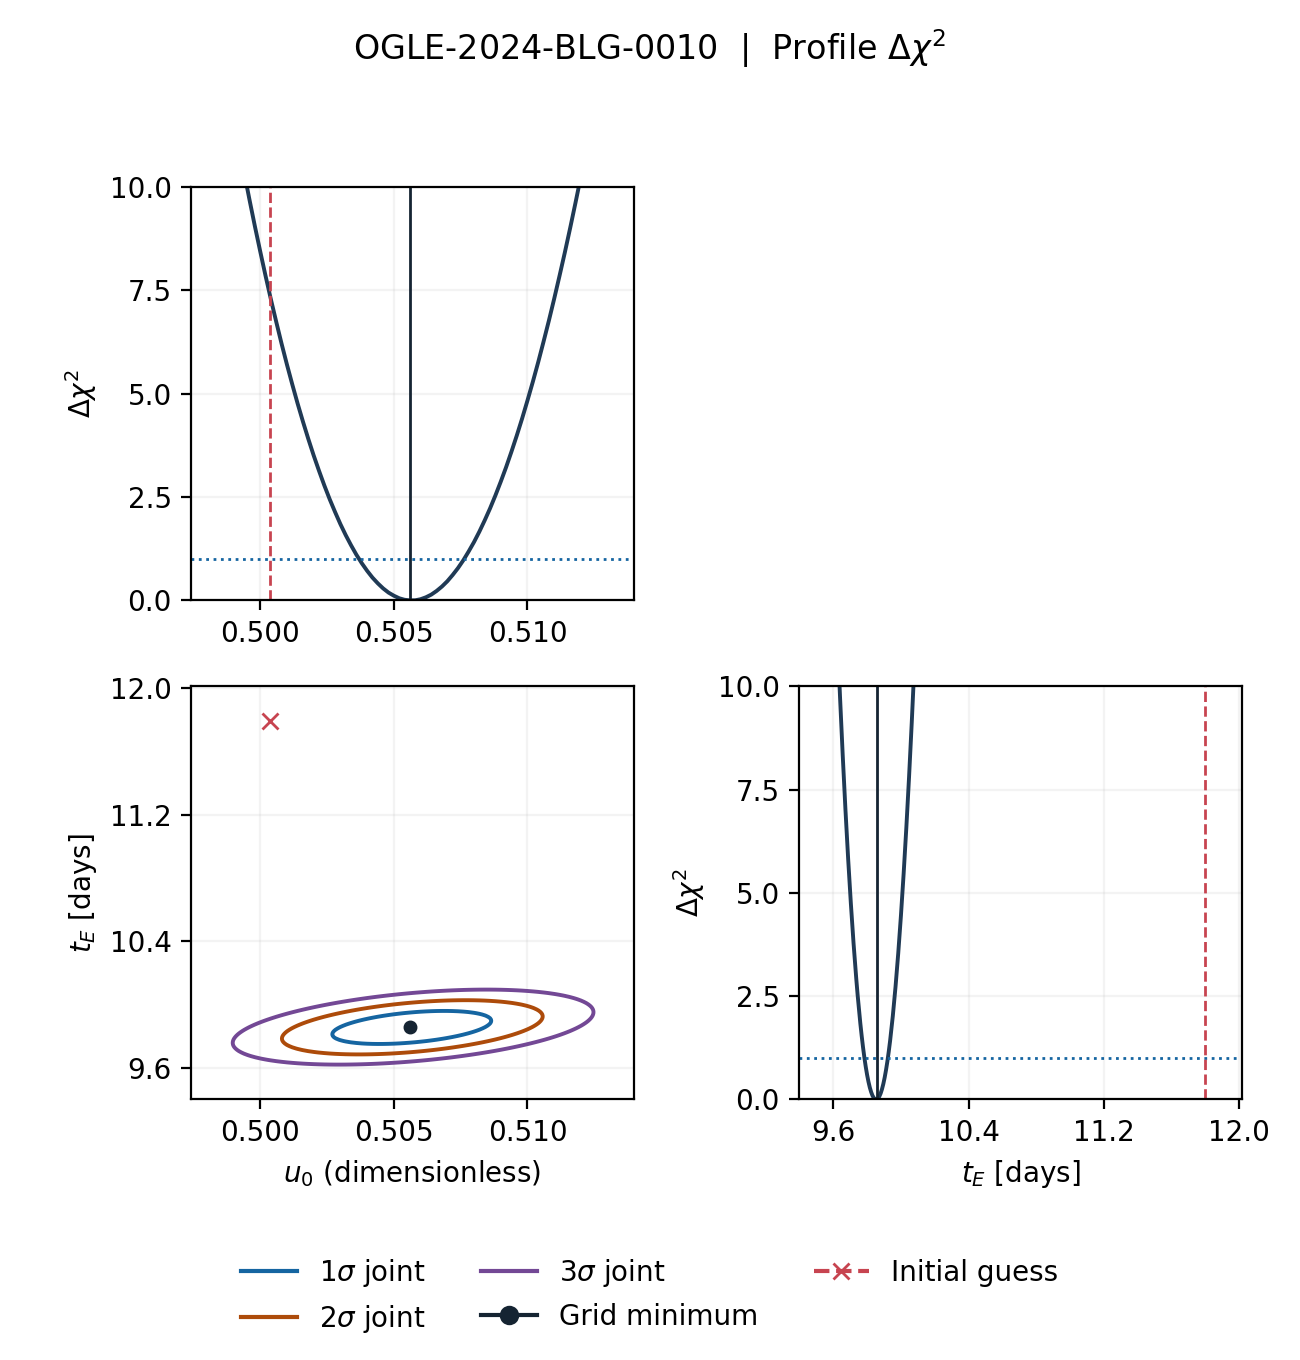

In [12]:
config = build_config(GUESSES, FIXED, GRID)
output = run_event(OGLE_URL, config, OUTPUT_DIR, ZOOM_HALF_WIDTH)
for filename in ("light_curve_full.png", "light_curve_event.png", "corner.png"):
    display(Image(filename=str(output / filename)))
